In [19]:
import numpy as np
import matplotlib.pyplot as plt

In [20]:
def finite_potential(x, a, V0):

    potential = np.where(np.abs(x) < a, 0, V0)

    return potential

In [21]:
def hamiltonian_matrix(N, dx, potential_values):

    C = 1 / (2 * dx**2)

    H = np.zeros((N, N))

    for i in range(N):

        H[i, i] = 2*C + potential_values[i]

        if i > 0:
            H[i, i-1] = -C

        if i < N-1:
            H[i, i+1] = -C

    return H

In [ ]:
def solve_finite_potential(L, a, V0, interior_points, number_of_states):

    if interior_points <= 0:
        raise ValueError("Interior points must be positive.")

    if L <= 0 or a <= 0 or a >= L:
        raise ValueError("Invalid L or a.")

    if number_of_states <= 0 or number_of_states > interior_points:
        raise ValueError("Invalid number of states.")

    dx = 2 * L / (interior_points + 1)

    x = np.linspace(-L + dx, L - dx, interior_points)

    x_full = np.linspace(-L, L, interior_points + 2)

    potential_values = finite_potential(x, a, V0)

    H = hamiltonian_matrix(interior_points, dx, potential_values)

    eigenvalues, eigenvectors = np.linalg.eigh(H)

    energies = eigenvalues[:number_of_states]

    wavefunctions = eigenvectors[:, :number_of_states]

    psi = np.zeros((len(x_full), number_of_states))

    psi[1:-1, :] = wavefunctions

    for i in range(number_of_states):

        norm = np.sqrt(np.sum(psi[:, i]**2) * dx)

        psi[:, i] = psi[:, i] / norm

    probability = psi**2

    print("Numerical energy eigenvalues:")

    for i, E in enumerate(energies):
        print(f"State {i+1}: {E:.6f}")

    return x_full, energies, psi, probability

In [23]:
L = 3
a = 1.0
V0 = 20.0

interior_points = 200
number_of_states = 3

x, energies, psi, probability = solve_finite_potential(
    L, a, V0, interior_points, number_of_states
)

Numerical energy eigenvalues:
State 1: 0.940675
State 2: 3.734773
State 3: 8.280332


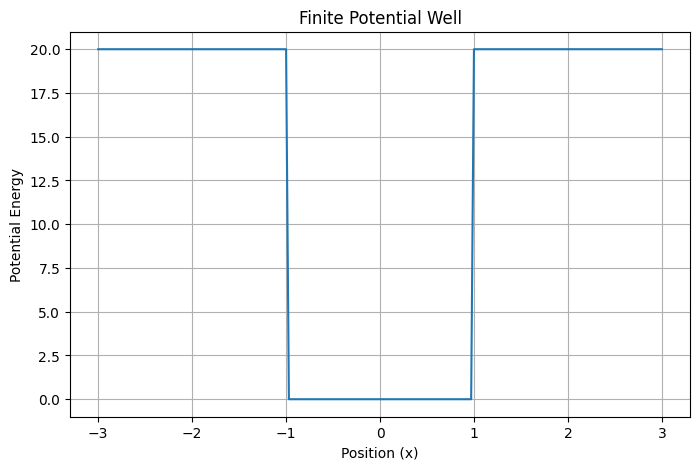

In [24]:
plt.figure(figsize=(8,5))

V = finite_potential(x, a, V0)

plt.plot(x, V)

plt.xlabel("Position (x)")
plt.ylabel("Potential Energy")
plt.title("Finite Potential Well")

plt.grid()
plt.show()

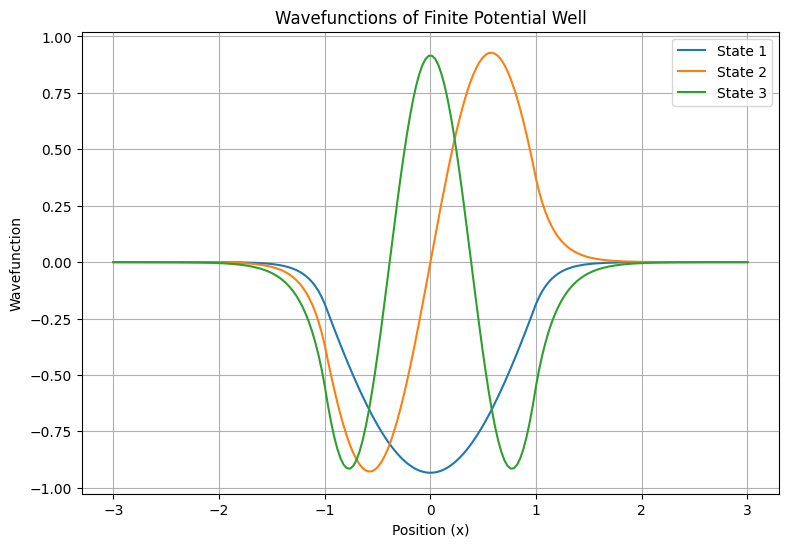

In [25]:
plt.figure(figsize=(9,6))

for i in range(number_of_states):

    plt.plot(x, psi[:, i], label=f"State {i+1}")

plt.xlabel("Position (x)")
plt.ylabel("Wavefunction")
plt.title("Wavefunctions of Finite Potential Well")

plt.legend()
plt.grid()
plt.show()

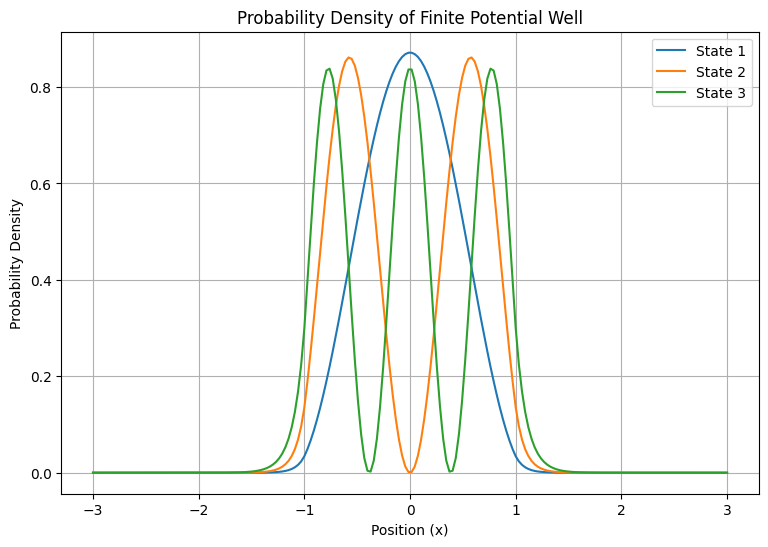

In [26]:
plt.figure(figsize=(9,6))

for i in range(number_of_states):

    plt.plot(x, probability[:, i], label=f"State {i+1}")

plt.xlabel("Position (x)")
plt.ylabel("Probability Density")
plt.title("Probability Density of Finite Potential Well")

plt.legend()
plt.grid()
plt.show()

In [27]:
print("Energy levels:")

for i in range(number_of_states):

    print(f"State {i+1}: {energies[i]:.6f}")

Energy levels:
State 1: 0.940675
State 2: 3.734773
State 3: 8.280332
